# 06 · Swing and Seam Analysis

Measure sideways movement in the air and off the pitch from a tracked ball path, and tell real movement apart from tracking noise.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. The problem with noise

A tracked ball position is never exact. Each point is off by a pixel or two. If we report every wobble as swing, every delivery will appear to swing. So each movement is compared with its own uncertainty, and it is reported as movement only when it is at least three times its standard error. Anything smaller is labelled "within tracking noise".

Swing is measured as the gap between where the ball was just before it bounced and where its early direction was pointing. Seam is measured as the change in sideways speed across the bounce.

The tracks here are synthetic pixel paths made by `sample_data.synthetic_track`. To use a real clip, track it in notebook 03 and pass `result["points"]` to the same functions.

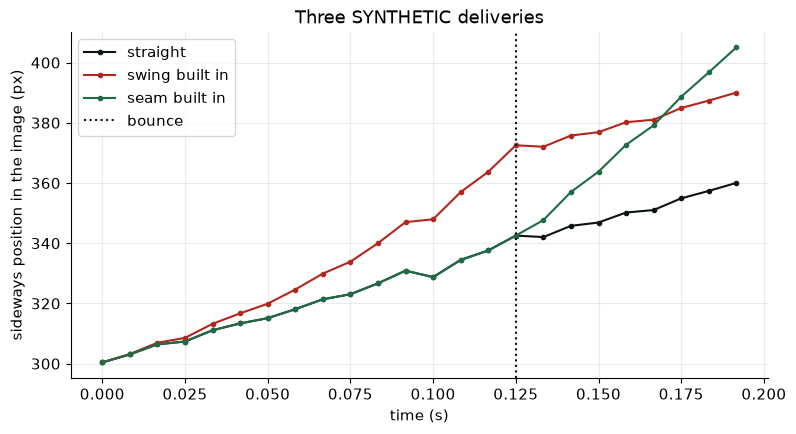

In [2]:
from pitchvision import trajectory, sample_data

straight = sample_data.synthetic_track(seed=1, noise=1.2)
swinging = sample_data.synthetic_track(seed=1, noise=1.2, swing=30)
seaming = sample_data.synthetic_track(seed=1, noise=1.2, seam=45)

fig, ax = plt.subplots()
for pts, label, colour in [(straight, "straight", INK), (swinging, "swing built in", RED), (seaming, "seam built in", GREEN)]:
    d = pd.DataFrame(pts); ax.plot(d["t"], d["x"], "o-", ms=3, color=colour, label=label)
ax.axvline(straight[15]["t"], color=INK, ls=":", label="bounce")
ax.set_xlabel("time (s)"); ax.set_ylabel("sideways position in the image (px)")
ax.set_title("Three SYNTHETIC deliveries"); ax.legend(); plt.show()

## 2. Noise filtering

A moving average replaces each point with the mean of itself and its neighbours. It removes jitter and keeps the shape. It also flattens sharp changes, which is why the bounce is found on the raw points and the filter is used only for drawing.

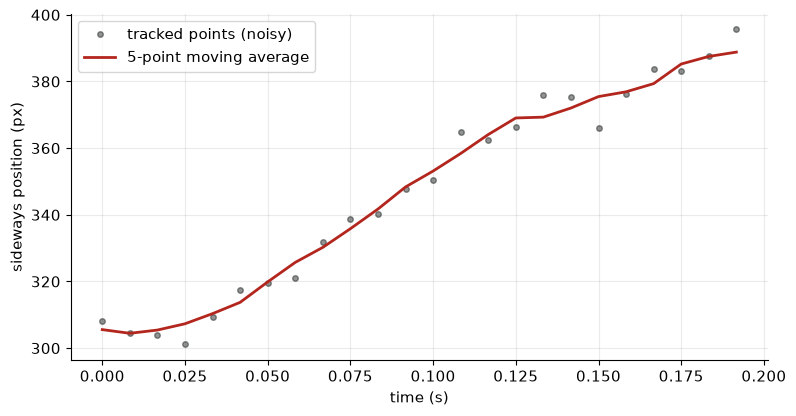

In [3]:
noisy = sample_data.synthetic_track(seed=3, noise=4.0, swing=30)
d = pd.DataFrame(noisy)
d["smoothed"] = trajectory.smooth_track(d["x"].tolist(), window=5)
by_hand = d["x"].rolling(5, center=True, min_periods=1).mean()
assert np.allclose(d["smoothed"], by_hand)                      # same as pandas' centred rolling mean

fig, ax = plt.subplots()
ax.plot(d["t"], d["x"], "o", ms=4, color=INK, alpha=0.45, label="tracked points (noisy)")
ax.plot(d["t"], d["smoothed"], color=RED, lw=2, label="5-point moving average")
ax.set_xlabel("time (s)"); ax.set_ylabel("sideways position (px)"); ax.legend(); plt.show()

## 3. Swing, step by step

1. Fit a straight line to the first half of the pre-bounce points. This is the initial direction.
2. Extend that line to the moment of the bounce.
3. Compare it with where the ball was (taken from a smooth curve through all the pre-bounce points, so one noisy point cannot decide the answer).
4. Divide the gap by its standard error to get z.

straight        deviation    3.1 px, standard error 2.2, z = 1.4 -> Within tracking noise
swing built in  deviation   20.0 px, standard error 2.2, z = 9.0 -> Lateral movement in the air detected


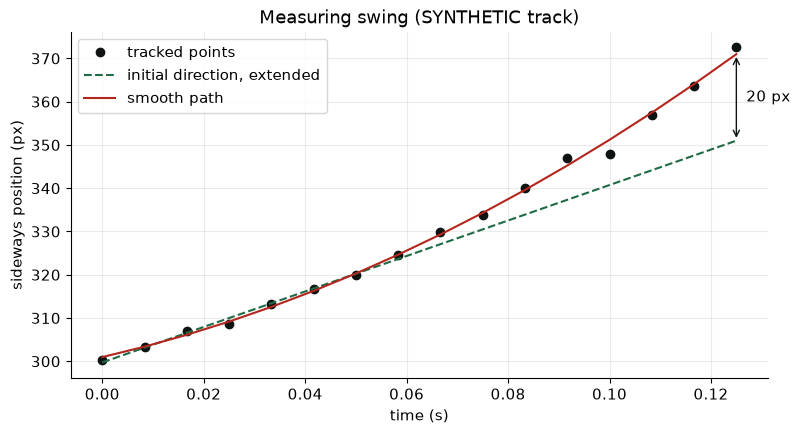

In [4]:
def swing_by_hand(points, bounce_index):
    pre = points[: bounce_index + 1]
    t = np.array([p["t"] for p in pre]); x = np.array([p["x"] for p in pre])
    half = max(3, len(t) // 2)
    line = np.polyfit(t[:half], x[:half], 1)                    # initial direction
    curve = np.polyfit(t, x, 2)                                 # smooth path
    deviation = np.polyval(curve, t[-1]) - np.polyval(line, t[-1])
    return deviation, line, curve, t, x

for name, pts in [("straight", straight), ("swing built in", swinging)]:
    dev, line, curve, t, x = swing_by_hand(pts, 15)
    m = trajectory.lateral_movement(pts, 15)
    assert abs(dev - m["swing"]["deviation"]) < 1e-6
    print(f"{name:15s} deviation {dev:6.1f} px, standard error {m['swing']['std_error']:.1f}, z = {m['swing']['z']:.1f} -> {m['swing']['label']}")

dev, line, curve, t, x = swing_by_hand(swinging, 15)
fig, ax = plt.subplots()
ax.plot(t, x, "o", color=INK, label="tracked points")
ax.plot(t, np.polyval(line, t), "--", color=GREEN, label="initial direction, extended")
ax.plot(t, np.polyval(curve, t), color=RED, label="smooth path")
ax.annotate("", xy=(t[-1], np.polyval(curve, t[-1])), xytext=(t[-1], np.polyval(line, t[-1])), arrowprops=dict(arrowstyle="<->", color=INK))
ax.text(t[-1], (np.polyval(curve, t[-1]) + np.polyval(line, t[-1])) / 2, f"  {dev:.0f} px", va="center")
ax.set_xlabel("time (s)"); ax.set_ylabel("sideways position (px)"); ax.set_title("Measuring swing (SYNTHETIC track)"); ax.legend(); plt.show()

## 4. Seam

Fit one straight line before the bounce and one after. Their slopes are the sideways speed before and after. The change between them, divided by its standard error, is tested the same way.

In [5]:
for name, pts in [("straight", straight), ("seam built in", seaming)]:
    s = trajectory.lateral_movement(pts, 15)["seam"]
    print(f"{name:14s} sideways speed {s['velocity_before']:7.0f} -> {s['velocity_after']:7.0f} px/s, change {s['change']:7.0f} "
          f"+/- {s['std_error']:.0f}, z = {s['z']:.1f} -> {s['label']}")

few = trajectory.lateral_movement(straight[:4])
print("\nWith four points:", few["swing"]["status"], "/", few["seam"]["status"])

straight       sideways speed     346 ->     277 px/s, change     -69 +/- 36, z = 1.9 -> Within tracking noise
seam built in  sideways speed     346 ->     952 px/s, change     606 +/- 36, z = 16.7 -> Change of direction off the pitch detected

With four points: insufficient / insufficient


## 5. Does the test behave?

Two checks on 300 synthetic deliveries each. First, deliveries with no movement built in: how often does the test wrongly report swing? Second, deliveries with more and more swing built in: how often is it found?

,swing built in (px),reported as swing (%)
0,0,2.3
1,4,5.0
2,8,14.7
3,12,33.3
4,16,62.7
5,24,95.0
6,32,99.7


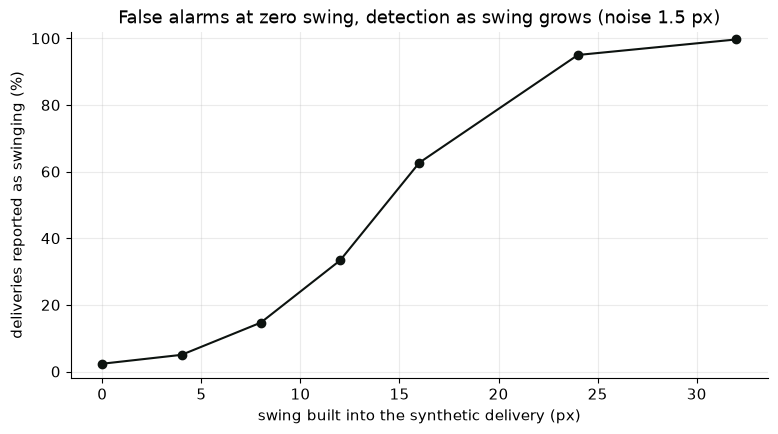

False-alarm rate with no swing: 2.3%


In [6]:
def detection_rate(swing_px, n=300, noise=1.5):
    found = 0
    for seed in range(n):
        m = trajectory.lateral_movement(sample_data.synthetic_track(seed=seed, noise=noise, swing=swing_px), 15)
        found += bool(m["swing"]["significant"])
    return found / n * 100

levels = [0, 4, 8, 12, 16, 24, 32]
rates = [detection_rate(s) for s in levels]
power = pd.DataFrame({"swing built in (px)": levels, "reported as swing (%)": rates}); display(power.round(1))

fig, ax = plt.subplots()
ax.plot(levels, rates, marker="o", color=INK)
ax.set_xlabel("swing built into the synthetic delivery (px)"); ax.set_ylabel("deliveries reported as swinging (%)")
ax.set_title("False alarms at zero swing, detection as swing grows (noise 1.5 px)"); ax.set_ylim(-2, 102); plt.show()
print(f"False-alarm rate with no swing: {rates[0]:.1f}%")

## 6. Comparing deliveries and sessions

Movement from one fixed camera can be compared between deliveries. Below, two synthetic 'sessions' of ten deliveries each, the second with more swing built in.

,mean_deviation_px,reported_as_swing
session,,
A,4.6,2
B,14.6,9


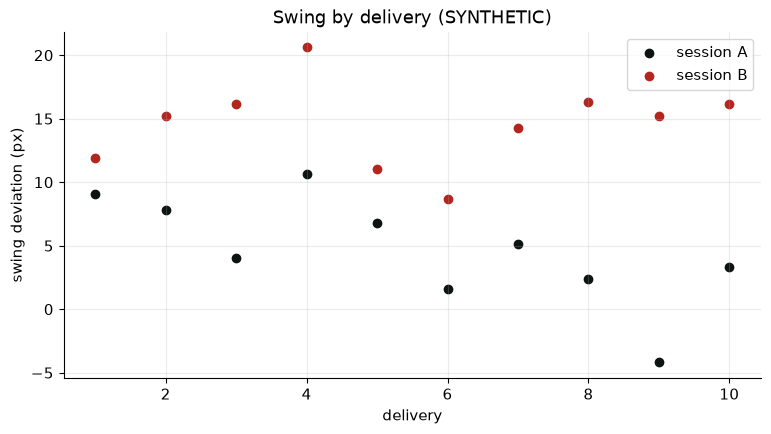

Values are in image pixels from one camera. They describe movement across the IMAGE, which mixes true sideways movement with perspective. Use them to compare deliveries filmed from the same fixed camera position, not as centimetres of swing.


In [7]:
rows = []
for session, base in [("A", 6), ("B", 22)]:
    for i in range(10):
        pts = sample_data.synthetic_track(seed=100 * (session == "B") + i, noise=1.5, swing=base + i % 4)
        b = trajectory.detect_bounce(pts)
        m = trajectory.lateral_movement(pts, b["index"] if b["found"] else None)
        rows.append({"session": session, "delivery": i + 1, "deviation_px": m["swing"]["deviation"], "z": m["swing"]["z"],
                     "reported": m["swing"]["label"]})
moves = pd.DataFrame(rows)
moves.to_csv(EXPORTS / "swing_by_delivery.csv", index=False)
summary = moves.groupby("session").agg(mean_deviation_px=("deviation_px", "mean"), reported_as_swing=("reported", lambda s: (s != "Within tracking noise").sum()))
display(summary.round(1))

fig, ax = plt.subplots()
for session, colour in [("A", INK), ("B", RED)]:
    g = moves[moves["session"] == session]
    ax.scatter(g["delivery"], g["deviation_px"], color=colour, label=f"session {session}")
ax.set_xlabel("delivery"); ax.set_ylabel("swing deviation (px)"); ax.legend(); ax.set_title("Swing by delivery (SYNTHETIC)"); plt.show()
print(trajectory.lateral_movement(straight, 15)["warning"])

## Summary

### Key findings
- Swing is the gap between the ball's actual position at the bounce and its initial line; seam is the change in sideways speed across the bounce.
- With no movement built in, the test reports swing in only a small percentage of synthetic deliveries; it finds nearly all deliveries once the built-in swing is several times the noise.
- With too few points the result is 'insufficient' and nothing is reported.

### Interpretation
The method answers a narrow question well: did this ball move sideways across the image by more than the tracking error? It is good for comparing a bowler's deliveries filmed from one fixed position.

### Limitations
- Values are in image pixels. Sideways movement across the image mixes true swing with perspective, so they are not centimetres of swing.
- A camera behind the bowler sees sideways movement best; a side-on camera barely sees it.
- The three-standard-error threshold is strict, so small real movement is reported as noise.
- Rates above come from synthetic tracks with evenly spread noise. Real tracking errors are not that tidy.

### How this notebook connects to the application
The Bowling Lab's Swing and seam tab lists each tracked delivery with these labels and values. `POST /api/video/track` runs `trajectory.detect_bounce` and `trajectory.lateral_movement` on the tracked points, and `GET /api/video/compare` puts two deliveries side by side.